# Customer Churn Analysis and Retention Insights Dashboard

## Step 1: Understanding the Raw Dataset

In this step, the raw Telco Customer Churn dataset will be loaded and inspected to understand its structure, columns, data types, data quality, missing values, duplicate records, and churn distribution before any cleaning or transformation is performed.


### Load the raw dataset

The Telco Customer Churn dataset is loaded from the `data/raw` folder into a Pandas DataFrame. The original file is kept unchanged so that all cleaning decisions can be reproduced and documented separately.


In [2]:
import pandas as pd

df = pd.read_csv(r"D:\Projects\customer-churn-analysis\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")

### Dataset dimensions

This check identifies the number of rows and columns in the raw dataset. Each row should represent one customer, while each column represents a customer attribute or the churn outcome.

In [3]:
df.shape

(7043, 21)

**Observation:** The raw dataset contains 7043 customer records and 21 columns. This confirms that the dataset was loaded successfully and provides the baseline size before data cleaning.

### Preview the dataset

The first few records are reviewed to confirm that the dataset loaded correctly, column names are meaningful, and each row represents one customer with their service, account, demographic, and churn information.

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Observation:** The raw dataset contains 7,043 customer records and 21 columns. All columns appear to have 7,043 non-null values based on the initial structure check. However, `TotalCharges` is stored as a text field despite representing monetary values, indicating that further inspection is required for blank strings or invalid numeric values before analysis.

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Observation:** The standard missing-value check found no null values in any column. However, this result does not rule out blank strings or whitespace-only values, particularly in the `TotalCharges` column, which is currently stored as text and requires further validation.

In [7]:
(df["TotalCharges"] == "").sum()

np.int64(0)

In [8]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [9]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [10]:
df.loc[
    pd.to_numeric(df["TotalCharges"], errors="coerce").isna(),
    "TotalCharges"
]

488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: TotalCharges, dtype: str

### Hidden missing values in `TotalCharges`

Although the standard missing-value check showed no null values, further inspection identified 11 whitespace-only entries in the `TotalCharges` column. These entries cannot be converted to numeric values and therefore represent hidden missing values. This issue must be addressed before performing charge-related analysis.

### Inspect records with hidden missing `TotalCharges` values

The affected customer records are reviewed to determine whether blank `TotalCharges` values are related to customer tenure or newly created accounts.

In [11]:
invalid_total_charges = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
).isna()

df.loc[
    invalid_total_charges,
    [
        "customerID",
        "tenure",
        "MonthlyCharges",
        "TotalCharges",
        "Churn"
    ]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


|

### Clean and convert `TotalCharges`

The `TotalCharges` column contains 11 whitespace-only values. Inspection confirmed that all affected customers have zero tenure, meaning they are newly registered customers with no accumulated charges yet. The whitespace values will therefore be converted to missing values, replaced with 0, and the column will be converted to a numeric data type.

In [12]:
df["TotalCharges"] = (
    df["TotalCharges"]
    .str.strip()
    .replace("", pd.NA)
)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

### Verify `TotalCharges` cleaning

The cleaned `TotalCharges` column is checked to confirm that it is numeric, contains no remaining missing values, and that no customer records were removed during the cleaning process.

In [13]:
df["TotalCharges"].dtype
df["TotalCharges"].isnull().sum()
df.shape


(7043, 21)

**Result:** The `TotalCharges` column was successfully converted from text to a numeric data type. The 11 hidden missing values were replaced with 0 after confirming that they belonged to zero-tenure customers. The cleaned dataset retains all 7,043 customer records and 21 columns.

In [14]:
df.duplicated().sum()
df["customerID"].duplicated().sum()

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    print(col)
    print(df[col].unique())
    print()

df["SeniorCitizen"].value_counts()
df["Churn"].value_counts()

customerID
<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection
<ArrowS

C:\Users\Acer\AppData\Local\Temp\ipykernel_3132\3676208169.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


Churn
No     5174
Yes    1869
Name: count, dtype: int64

## Data Cleaning Summary

The dataset was validated and cleaned before analysis. No duplicate records or duplicate customer IDs were found. Standard missing-value checks showed no null values; however, 11 hidden whitespace-only values were identified in `TotalCharges`. These records belonged to customers with zero tenure, so their total charges were replaced with 0. The `TotalCharges` column was then converted to numeric format.

All categorical columns were reviewed and contained consistent, expected values. Categories such as `No internet service` and `No phone service` were retained because they represent cases where a service is not applicable rather than a customer declining an available service.

The final cleaned dataset contains 7,043 unique customer records and 21 columns and is ready for exploratory data analysis.


In [15]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [16]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

In [17]:
df.groupby("tenure_group", observed=True)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

tenure_group
0-12     47.678161
13-24    28.710938
25-48    20.388959
49-72     9.513176
Name: Churn, dtype: float64

In [18]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"],
    include_lowest=True
)

In [19]:
churn_by_tenure = df.groupby(
    "tenure_group",
    observed=True
)["Churn"].apply(lambda x: (x == "Yes").mean() * 100)

churn_by_tenure

tenure_group
0–12     47.438243
13–24    28.710938
25–48    20.388959
49–72     9.513176
Name: Churn, dtype: float64

In [20]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [21]:
churn_by_contract = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

churn_by_contract

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

In [22]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


**Insight:** Contract type has a strong association with churn. Month-to-month customers have the highest churn rate at 42.7% and represent the largest contract group. In contrast, churn declines to 11.3% for one-year contracts and 2.8% for two-year contracts. Month-to-month customers account for approximately 88.5% of all churned customers, making them the highest-priority segment for retention efforts.

In [23]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [24]:
df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64

**Insight:** Internet-service type is strongly associated with churn. Fiber-optic customers have the highest churn rate at approximately 41.9%, compared with 19.0% for DSL customers and 7.4% for customers without internet service. Because fiber optic is also the largest internet-service group, it should be investigated further as a high-priority retention segment.

In [25]:
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [26]:
df.groupby("TechSupport")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: Churn, dtype: float64

In [27]:
pd.crosstab(df["TechSupport"], df["Churn"])

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


**Insight:** Technical-support status is strongly associated with churn among customers with internet service. Customers without technical support have a churn rate of 41.6%, compared with 15.2% for customers with technical support. This suggests that customers without technical support are a high-priority group for retention analysis.

In [28]:
df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 40, 80, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df["MonthlyChargeGroup"].value_counts().sort_index()

MonthlyChargeGroup
Low       1838
Medium    2539
High      2666
Name: count, dtype: int64

In [29]:
df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 40, 80, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df["MonthlyChargeGroup"].value_counts().sort_index()

MonthlyChargeGroup
Low       1838
Medium    2539
High      2666
Name: count, dtype: int64

In [30]:
churn_by_charge = df.groupby("MonthlyChargeGroup", observed=True)["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

churn_by_charge

,Customers,Churned_Customers,Churn_Rate
MonthlyChargeGroup,,,
Low,1838,214,11.643090
Medium,2539,749,29.499803
High,2666,906,33.983496


**Insight:** Churn rises as monthly charges increase. Customers in the high monthly-charge group have a churn rate of approximately 34.0%, nearly three times the rate of customers in the low-charge group at 11.6%. This indicates that pricing or perceived plan value should be investigated further, particularly for high-charge customers.

In [31]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [32]:
churn_by_payment = df.groupby("PaymentMethod")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

churn_by_payment

,Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.709845
Credit card (automatic),1522,232,15.243101
Electronic check,2365,1071,45.285412
Mailed check,1612,308,19.106700


**Insight:** Payment method is strongly associated with churn. Electronic-check customers have the highest churn rate at approximately 45.3%, compared with 15.2% to 19.1% for customers using other payment methods. Electronic-check users account for approximately 57.3% of all churned customers, making them an important group for further investigation.

In [33]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [34]:
churn_by_payment = df.groupby("OnlineSecurity")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

churn_by_payment

,Customers,Churned_Customers,Churn_Rate
OnlineSecurity,,,
No,3498,1461,41.766724
No internet service,1526,113,7.404980
Yes,2019,295,14.611194


**Insight:** Online-security status is strongly associated with churn among customers with internet service. Customers without online security have a churn rate of approximately 41.8%, compared with 14.6% for customers who subscribe to online security. This suggests that customers without online security are another high-priority group for retention analysis.

In [35]:
df.groupby("gender")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

,Customers,Churned_Customers,Churn_Rate
gender,,,
Female,3488,939,26.920872
Male,3555,930,26.160338


In [36]:
df.groupby("SeniorCitizen")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

,Customers,Churned_Customers,Churn_Rate
SeniorCitizen,,,
0,5901,1393,23.606168
1,1142,476,41.681261


In [37]:
df.groupby("Partner")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

,Customers,Churned_Customers,Churn_Rate
Partner,,,
No,3641,1200,32.957979
Yes,3402,669,19.664903


In [38]:
df.groupby("Dependents")["Churn"].agg(
    Customers="count",
    Churned_Customers=lambda x: (x == "Yes").sum(),
    Churn_Rate=lambda x: (x == "Yes").mean() * 100
)

,Customers,Churned_Customers,Churn_Rate
Dependents,,,
No,4933,1543,31.279140
Yes,2110,326,15.450237


In [39]:
high_risk = df[
    (df["Contract"] == "Month-to-month") &
    (df["tenure"] <= 12) &
    (df["InternetService"] == "Fiber optic") &
    (df["TechSupport"] == "No")
]

print("Total customers:", len(high_risk))
print("Churned customers:", (high_risk["Churn"] == "Yes").sum())
print("Churn rate:", (high_risk["Churn"] == "Yes").mean() * 100)

Total customers: 833
Churned customers: 592
Churn rate: 71.06842737094838


### High-risk segment 1: Month-to-month + Fiber optic + No technical support

In [40]:
overall_churn_rate = (df["Churn"] == "Yes").mean() * 100

print("Overall churn rate:", overall_churn_rate)

Overall churn rate: 26.536987079369588


In [41]:
segment_2 = df[
    (df["Contract"] == "Month-to-month") &
    (df["PaymentMethod"] == "Electronic check")
]

print("Total customers:", len(segment_2))
print("Churned customers:", (segment_2["Churn"] == "Yes").sum())
print("Churn rate:", (segment_2["Churn"] == "Yes").mean() * 100)

Total customers: 1850
Churned customers: 994
Churn rate: 53.729729729729726


### High-risk segment 2: Month-to-month + Electronic check

In [42]:
segment_3 = df[
    (df["Contract"] == "Month-to-month") &
    (df["OnlineSecurity"] == "No")
]

print("Total customers:", len(segment_3))
print("Churned customers:", (segment_3["Churn"] == "Yes").sum())
print("Churn rate:", (segment_3["Churn"] == "Yes").mean() * 100)

Total customers: 2631
Churned customers: 1343
Churn rate: 51.04522995058913


### High-risk segment 3: Month-to-month + No online security

## Combined High-Risk Customer Segments

| Segment | Customer conditions | Total customers | Churned customers | Churn rate |
|---|---|---:|---:|---:|
| Segment 1 | Month-to-month + Short tenure (≤12 months) + Fiber optic + No technical support | 833 | 592 | 71.07% |
| Segment 2 | Month-to-month + Electronic check | 1,850 | 994 | 53.73% |
| Segment 3 | Month-to-month + No online security | 2,631 | 1,343 | 51.05% |
| Overall customer base | All customers | 7,043 | 1,869 | 26.54% |

**Insight:** Combined customer characteristics identify substantially higher churn rates than the overall customer base. The highest-risk segment had a churn rate of 71.07%, compared with the overall churn rate of 26.54%. This indicates that customers with multiple observed risk factors show a much higher level of churn in this dataset.

**Insight:** Combined customer characteristics identify substantially higher-risk churn segments than any individual feature alone. The highest-risk segment had a churn rate of 71.07%, compared with the overall churn rate of 26.54%. This indicates that retention efforts should prioritize customers who display multiple risk factors rather than relying on only one characteristic.

In [43]:
total_monthly_revenue = df["MonthlyCharges"].sum()

print("Total monthly revenue:", total_monthly_revenue)

Total monthly revenue: 456116.6


In [44]:
churned_monthly_revenue = df.loc[
    df["Churn"] == "Yes",
    "MonthlyCharges"
].sum()

print("Monthly revenue from churned customers:", churned_monthly_revenue)

Monthly revenue from churned customers: 139130.85


In [45]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

## Visualizations

### 1. Overall Customer Churn Distribution

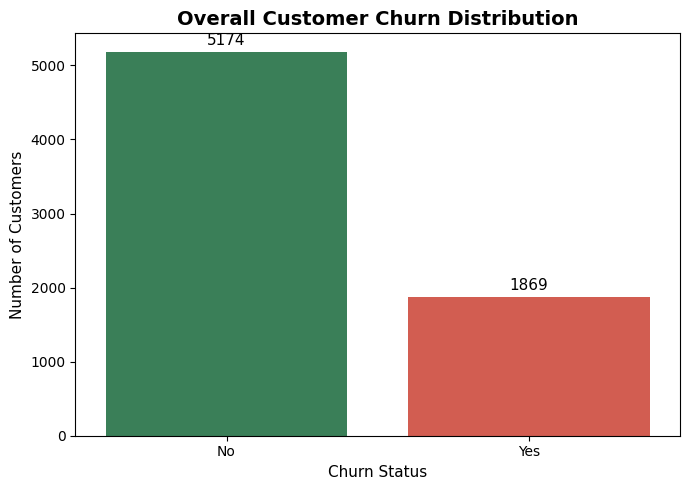

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='Churn',
    hue='Churn',
    palette={'No': '#2E8B57', 'Yes': '#E74C3C'},
    legend=False
)

plt.title('Overall Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn Status', fontsize=11)
plt.ylabel('Number of Customers', fontsize=11)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=11)

plt.tight_layout()
plt.show()

**Interpretation:** Out of 7,043 customers, 1,869 customers churned, resulting in an overall churn rate of 26.54%. Although retained customers represent the majority, more than one in four customers left the company. This establishes churn as a meaningful business problem that requires targeted retention strategies.

In [49]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'tenure_group', 'MonthlyChargeGroup'],
      dtype='str')

In [50]:
tenure_churn = (
    df.groupby('tenure')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

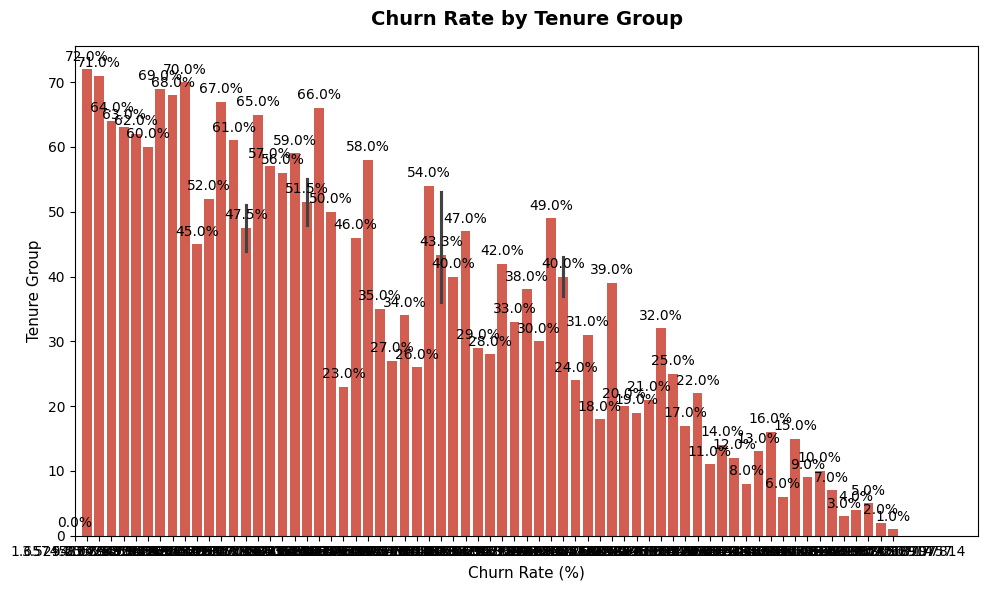

In [52]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=tenure_churn,
    y='tenure',
    x='Churn_Rate',
    color='#E74C3C'
)

plt.title('Churn Rate by Tenure Group', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Rate (%)', fontsize=11)
plt.ylabel('Tenure Group', fontsize=11)

plt.xlim(0, tenure_churn['Churn_Rate'].max() + 12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Customers with shorter tenure have the highest churn rate. Churn decreases as tenure increases, indicating that the company is most likely to lose customers during the early stages of the customer relationship. Retention efforts should therefore focus on onboarding, first-year satisfaction, and early renewal incentives.

### 3. Churn Rate by Contract Type

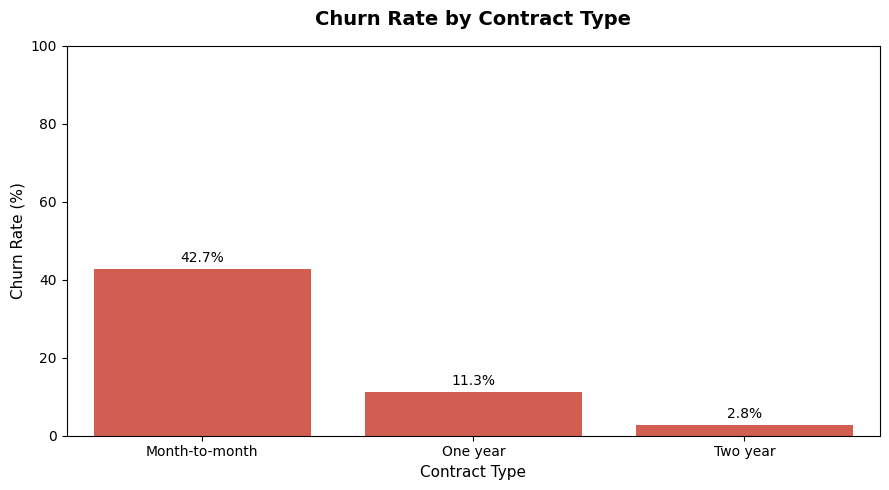

In [53]:
contract_churn = (
    df.groupby('Contract')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

contract_order = ['Month-to-month', 'One year', 'Two year']

contract_churn['Contract'] = pd.Categorical(
    contract_churn['Contract'],
    categories=contract_order,
    ordered=True
)

contract_churn = contract_churn.sort_values('Contract')

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contract_churn,
    x='Contract',
    y='Churn_Rate',
    color='#E74C3C'
)

plt.title('Churn Rate by Contract Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Customers with month-to-month contracts have the highest churn rate by a substantial margin. Customers on one-year and two-year contracts are much more likely to remain with the company. This indicates that encouraging customers to move from month-to-month plans to longer-term contracts should be a key retention strategy.

### 4. Churn Rate by Internet Service Type

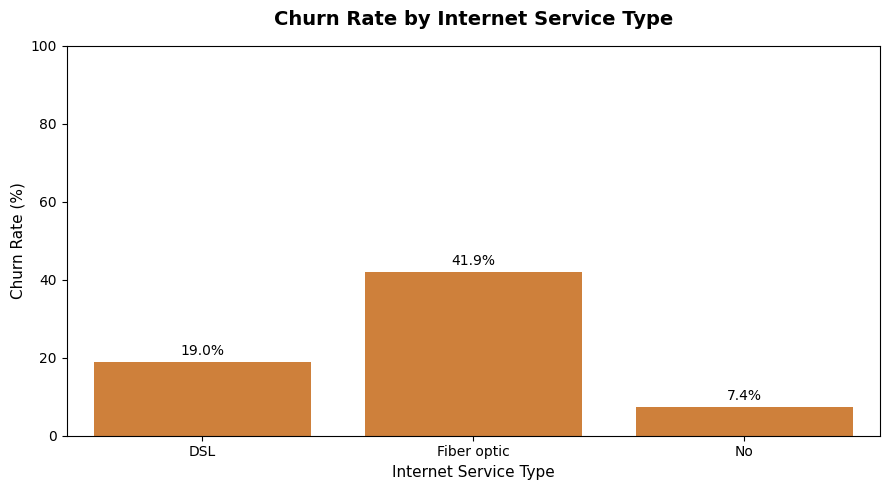

In [55]:
internet_churn = (
    df.groupby('InternetService')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

internet_order = ['DSL', 'Fiber optic', 'No']

internet_churn['InternetService'] = pd.Categorical(
    internet_churn['InternetService'],
    categories=internet_order,
    ordered=True
)

internet_churn = internet_churn.sort_values('InternetService')

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=internet_churn,
    x='InternetService',
    y='Churn_Rate',
    color='#E67E22'
)

plt.title('Churn Rate by Internet Service Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Internet Service Type', fontsize=11)
plt.ylabel('Churn Rate (%)', fontsize=11)
plt.ylim(0, 100)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Fiber-optic customers have the highest churn rate among internet-service categories. DSL customers have a lower churn rate, while customers without internet service have the lowest churn rate. This suggests that the company should investigate potential pricing, service-quality, or expectation issues among fiber-optic customers.

### 5. Churn Rate by Payment Method

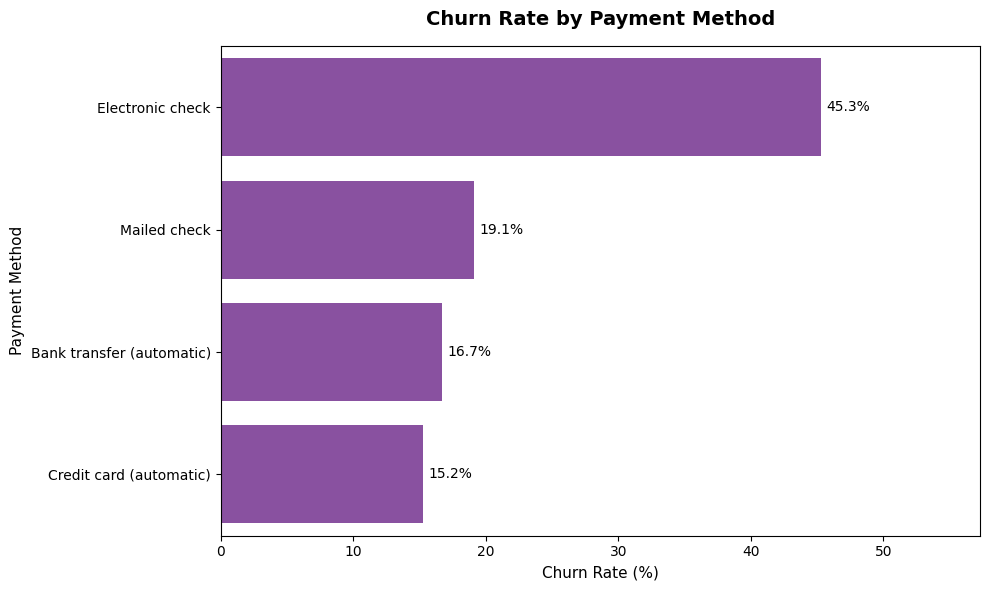

In [56]:
payment_churn = (
    df.groupby('PaymentMethod')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

payment_order = [
    'Electronic check',
    'Mailed check',
    'Bank transfer (automatic)',
    'Credit card (automatic)'
]

payment_churn['PaymentMethod'] = pd.Categorical(
    payment_churn['PaymentMethod'],
    categories=payment_order,
    ordered=True
)

payment_churn = payment_churn.sort_values('Churn_Rate', ascending=True)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=payment_churn,
    y='PaymentMethod',
    x='Churn_Rate',
    color='#8E44AD'
)

plt.title('Churn Rate by Payment Method', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Rate (%)', fontsize=11)
plt.ylabel('Payment Method', fontsize=11)
plt.xlim(0, payment_churn['Churn_Rate'].max() + 12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Customers who use electronic checks have the highest churn rate among all payment methods. Customers who use automatic payment methods, such as automatic bank transfers and credit cards, have lower churn rates. This suggests that the company should encourage eligible electronic-check customers to adopt automatic payment options.

### 6. Churn Rate by Technical Support Status

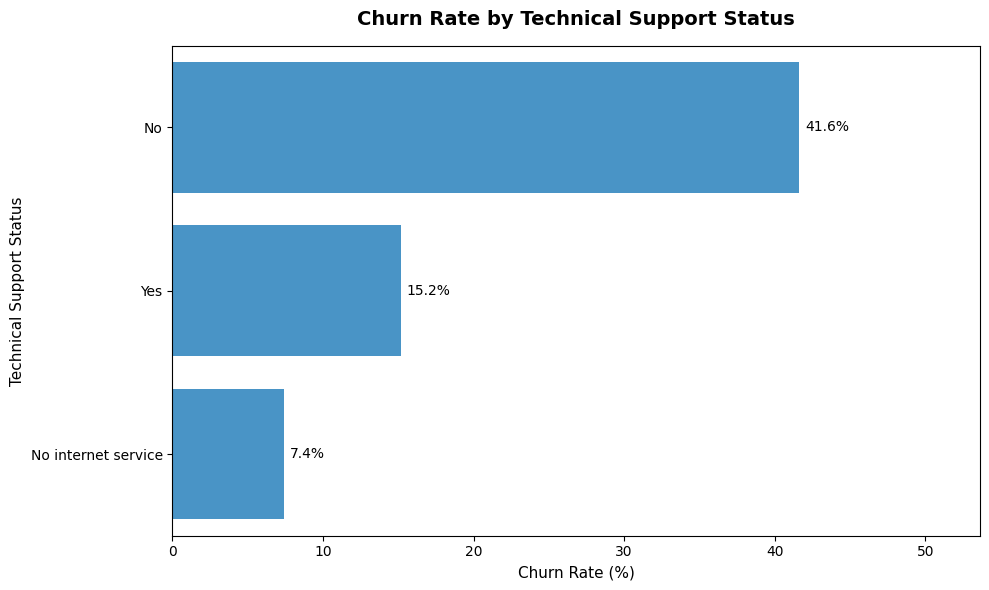

In [57]:
techsupport_churn = (
    df.groupby('TechSupport')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

techsupport_order = ['No', 'Yes', 'No internet service']

techsupport_churn['TechSupport'] = pd.Categorical(
    techsupport_churn['TechSupport'],
    categories=techsupport_order,
    ordered=True
)

techsupport_churn = techsupport_churn.sort_values('TechSupport')

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=techsupport_churn,
    y='TechSupport',
    x='Churn_Rate',
    color='#3498DB'
)

plt.title('Churn Rate by Technical Support Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Rate (%)', fontsize=11)
plt.ylabel('Technical Support Status', fontsize=11)
plt.xlim(0, techsupport_churn['Churn_Rate'].max() + 12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Customers without technical support have the highest churn rate. Customers who subscribe to technical support have a substantially lower churn rate. Customers without internet service should be interpreted separately because technical support is not applicable to them. This finding suggests that proactive support, troubleshooting, and technical-service bundles could help reduce customer churn.

### 7. Churn Rate by Online Security Status

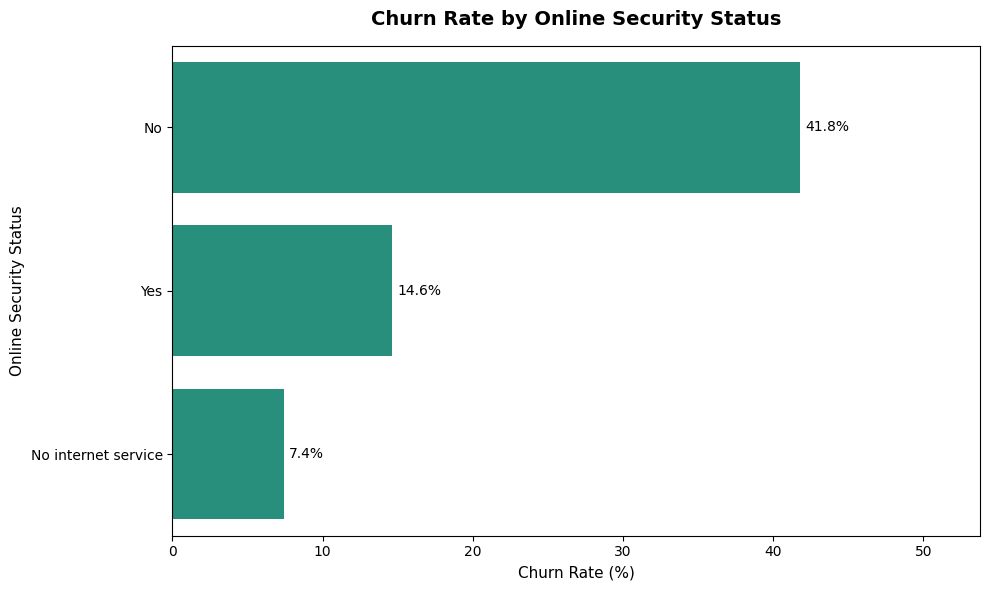

In [58]:
security_churn = (
    df.groupby('OnlineSecurity')['Churn']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='Churn_Rate')
)

security_order = ['No', 'Yes', 'No internet service']

security_churn = security_churn.sort_values(
    'OnlineSecurity',
    key=lambda x: x.map({value: i for i, value in enumerate(security_order)})
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=security_churn,
    y='OnlineSecurity',
    x='Churn_Rate',
    order=security_order,
    color='#16A085'
)

plt.title('Churn Rate by Online Security Status',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Rate (%)', fontsize=11)
plt.ylabel('Online Security Status', fontsize=11)
plt.xlim(0, security_churn['Churn_Rate'].max() + 12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** Customers without online security have a substantially higher churn rate than customers with online security. Customers with no internet service should be interpreted separately because online security is not applicable to them. This suggests that online-security bundles may support customer retention, particularly among customers who already use internet services.

### 8. Combined High-Risk Segment Comparison

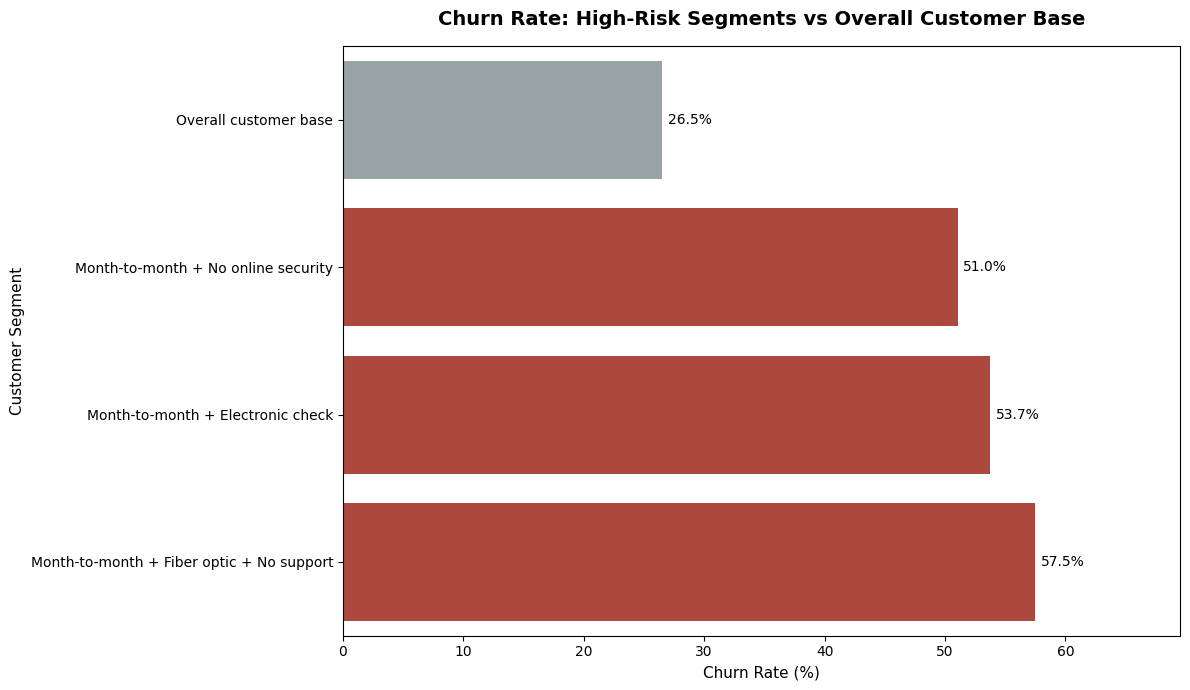

In [59]:
overall_churn_rate = (df['Churn'] == 'Yes').mean() * 100

segment_results = []

segment_definitions = {
    'Month-to-month + Fiber optic + No support': (
        (df['Contract'] == 'Month-to-month') &
        (df['InternetService'] == 'Fiber optic') &
        (df['TechSupport'] == 'No')
    ),
    'Month-to-month + Electronic check': (
        (df['Contract'] == 'Month-to-month') &
        (df['PaymentMethod'] == 'Electronic check')
    ),
    'Month-to-month + No online security': (
        (df['Contract'] == 'Month-to-month') &
        (df['OnlineSecurity'] == 'No')
    )
}

for segment_name, condition in segment_definitions.items():
    segment = df[condition]

    segment_results.append({
        'Segment': segment_name,
        'Churn_Rate': (segment['Churn'] == 'Yes').mean() * 100
    })

segment_churn = pd.DataFrame(segment_results)

segment_churn = pd.concat([
    segment_churn,
    pd.DataFrame([{
        'Segment': 'Overall customer base',
        'Churn_Rate': overall_churn_rate
    }])
], ignore_index=True)

segment_churn = segment_churn.sort_values('Churn_Rate', ascending=True)

plt.figure(figsize=(12, 7))

colors = [
    '#95A5A6' if segment == 'Overall customer base' else '#C0392B'
    for segment in segment_churn['Segment']
]

ax = sns.barplot(
    data=segment_churn,
    y='Segment',
    x='Churn_Rate',
    hue='Segment',
    palette=dict(zip(segment_churn['Segment'], colors)),
    legend=False
)

plt.title('Churn Rate: High-Risk Segments vs Overall Customer Base',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Churn Rate (%)', fontsize=11)
plt.ylabel('Customer Segment', fontsize=11)
plt.xlim(0, segment_churn['Churn_Rate'].max() + 12)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

**Interpretation:** The combined high-risk segments have substantially higher churn rates than the overall customer base. This confirms that customers with multiple risk factors should receive priority retention attention. Instead of targeting every customer equally, the company can focus on month-to-month customers who also use high-risk payment, internet-service, or support configurations.